In [ ]:
# ============================================================
# CELDA 1: Configuración del entorno
# ============================================================

# --- 1. Verificar que hay GPU ---
import subprocess, sys

result = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                        capture_output=True, text=True)
if result.returncode != 0:
    raise RuntimeError(
        "No se detectó GPU. Ve a: Entorno de ejecución > Cambiar tipo de entorno > T4 GPU, "
        "y vuelve a ejecutar la celda."
    )
print("GPU detectada:", result.stdout.strip())

# --- 2. Instalar dependencias ---
# ultralytics trae YOLO11 y el tracker ByteTrack integrado.
# supervision aporta lectura/escritura de video, anotadores y LineZone (verificación cruzada).
!pip install -q ultralytics supervision

# --- 3. Imports y verificación de CUDA ---
import torch
import cv2
import numpy as np
import pandas as pd
import ultralytics
import supervision as sv

assert torch.cuda.is_available(), "PyTorch no ve la GPU: reinicia el entorno de ejecución y reintenta."

# --- 4. Registrar versiones (reproducibilidad) ---
print("\n--- Versiones ---")
print(f"Python       : {sys.version.split()[0]}")
print(f"torch        : {torch.__version__}  (CUDA {torch.version.cuda})")
print(f"ultralytics  : {ultralytics.__version__}")
print(f"supervision  : {sv.__version__}")
print(f"opencv       : {cv2.__version__}")
print(f"numpy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")

# --- 5. Parámetros globales de la PoC (un solo lugar para ajustar) ---
CONFIG = {
    "model_name": "yolo11m.pt",   # cambiar a yolo11s.pt si el FPS es insuficiente
    "imgsz": 640,
    "conf": 0.3,                  # bajo a propósito: ByteTrack aprovecha detecciones débiles
    "iou": 0.7,                   # umbral de NMS
    "classes": [0],               # 0 = person en COCO
    "half": True,                 # FP16 en GPU
    "tracker": "bytetrack.yaml",
    "output_dir": "/content/output",
}

import os
os.makedirs(CONFIG["output_dir"], exist_ok=True)

# --- 6. Prueba rápida: cargar el modelo y hacer un "calentamiento" ---
from ultralytics import YOLO

model = YOLO(CONFIG["model_name"])   # descarga los pesos la primera vez (~40 MB)
dummy = np.zeros((640, 640, 3), dtype=np.uint8)
_ = model.predict(dummy, imgsz=CONFIG["imgsz"], half=CONFIG["half"], verbose=False)

print(f"\nModelo {CONFIG['model_name']} cargado y calentado en GPU.")
print("Entorno listo.")

GPU detectada: Tesla T4, 15360 MiB
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings

--- Versiones ---
Python       : 3.13.16
torch        : 2.14.1+cu130  (CUDA 13.0)
ultralytics  : 8.4.208
supervision  : 0.31.5
opencv       : 4.14.0
numpy        : 2.4.6
pandas       : 2.2.3
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

Modelo yolo11m.pt cargado y calentado en GPU.
Entorno listo.


MODULOS DE PIPELINE


In [ ]:
%%writefile crossing_counter.py
from dataclasses import dataclass
import numpy as np


@dataclass
class TrackState:
    side: int = 0            # ultimo lado confirmado (+1 / -1); 0 = sin confirmar
    anchor: tuple = None     # ultimo punto confirmado en ese lado
    first_frame: int = 0
    last_frame: int = 0
    n_crossings: int = 0
    counted: bool = False


def _ccw(a, b, c):
    return (c[1] - a[1]) * (b[0] - a[0]) > (b[1] - a[1]) * (c[0] - a[0])


def segments_intersect(p1, p2, p3, p4):
    """True si el segmento p1-p2 intersecta al segmento p3-p4."""
    return (_ccw(p1, p3, p4) != _ccw(p2, p3, p4)) and (_ccw(p1, p2, p3) != _ccw(p1, p2, p4))


class CrossingCounter:
    def __init__(self, a, b, hysteresis_px=8.0, count_once_per_id=True,
                 invert=False, stale_after=150):
        self.a = np.asarray(a, dtype=float)
        self.b = np.asarray(b, dtype=float)
        self.ab = self.b - self.a
        self.length = float(np.linalg.norm(self.ab))
        assert self.length > 0, "A y B no pueden ser el mismo punto"
        self.h = float(hysteresis_px)
        self.count_once = count_once_per_id
        self.invert = invert
        self.stale_after = stale_after

        self.tracks = {}
        self.count_in = 0
        self.count_out = 0
        self.events = []
        self.all_ids = set()
        self.finished_durations = []
        self.dubious_ids = set()

    def signed_distance(self, p):
        """Distancia con signo (px) del punto p a la recta AB (producto cruz 2D / |AB|)."""
        s = self.ab[0] * (p[1] - self.a[1]) - self.ab[1] * (p[0] - self.a[0])
        return s / self.length

    def update(self, frame_idx, ids, points, confs=None):
        new_events = []
        for i, (tid, p) in enumerate(zip(ids, points)):
            tid = int(tid)
            p = (float(p[0]), float(p[1]))
            self.all_ids.add(tid)
            st = self.tracks.get(tid)
            if st is None:
                st = TrackState(first_frame=frame_idx)
                self.tracks[tid] = st
            st.last_frame = frame_idx

            d = self.signed_distance(p)
            if abs(d) < self.h:            # banda muerta: no se decide nada
                continue
            side = 1 if d > 0 else -1

            if st.side == 0:               # primer lado confirmado
                st.side, st.anchor = side, p
                continue
            if side == st.side:            # sigue del mismo lado
                st.anchor = p
                continue

            # cambio de lado confirmado: validar que el movimiento corta el SEGMENTO AB
            prev, anchor = st.side, st.anchor
            st.side, st.anchor = side, p
            if not segments_intersect(anchor, p, self.a, self.b):
                continue

            direction = "IN" if (prev > 0 and side < 0) else "OUT"
            if self.invert:
                direction = "OUT" if direction == "IN" else "IN"

            st.n_crossings += 1
            if st.n_crossings > 1:
                self.dubious_ids.add(tid)
            counted = not (self.count_once and st.counted)
            if counted:
                st.counted = True
                if direction == "IN":
                    self.count_in += 1
                else:
                    self.count_out += 1

            ev = {"frame_idx": frame_idx, "track_id": tid, "direction": direction,
                  "x": round(p[0], 1), "y": round(p[1], 1),
                  "confidence": None if confs is None else round(float(confs[i]), 3),
                  "counted": counted, "n_crossings_id": st.n_crossings}
            self.events.append(ev)
            new_events.append(ev)

        if frame_idx % 100 == 0:
            self._cleanup(frame_idx)
        return new_events

    def _cleanup(self, frame_idx):
        stale = [t for t, s in self.tracks.items() if s.last_frame < frame_idx - self.stale_after]
        for t in stale:
            s = self.tracks.pop(t)
            self.finished_durations.append(s.last_frame - s.first_frame + 1)

    def summary(self, fps=None):
        durs = list(self.finished_durations) + [
            s.last_frame - s.first_frame + 1 for s in self.tracks.values()]
        mean_len = float(np.mean(durs)) if durs else 0.0
        return {
            "count_in": self.count_in,
            "count_out": self.count_out,
            "net": self.count_in - self.count_out,
            "unique_tracks": len(self.all_ids),
            "mean_track_len_frames": round(mean_len, 1),
            "mean_track_len_s": round(mean_len / fps, 2) if fps else None,
            "dubious_ids": sorted(self.dubious_ids),
        }

Writing crossing_counter.py


In [ ]:
%%writefile pipeline.py
"""Pipeline de conteo de personas por linea virtual.

Flujo por frame:  frame -> (YOLO11 + ByteTrack) -> CrossingCounter -> overlay -> writer
El generador de frames es intercambiable: en Colab se usa `iter_tracked_frames`
(ultralytics); en los tests se usa un generador sintetico.
"""
import json
import os
import shutil
import subprocess
import time
from collections import defaultdict, deque

import cv2
import numpy as np
import pandas as pd

FONT = cv2.FONT_HERSHEY_SIMPLEX
GREEN, YELLOW, WHITE, BLACK = (80, 200, 80), (0, 220, 255), (255, 255, 255), (0, 0, 0)
PALETTE = [(255, 160, 40), (60, 60, 230), (200, 80, 200), (60, 200, 230),
           (230, 200, 60), (90, 230, 120), (240, 120, 160), (120, 160, 255)]


# ---------------------------------------------------------------- geometria
def anchor_points(xyxy):
    """Centro del borde inferior de cada bbox (los 'pies'). Forma (N, 2)."""
    xyxy = np.asarray(xyxy, dtype=float).reshape(-1, 4)
    return np.stack([(xyxy[:, 0] + xyxy[:, 2]) / 2.0, xyxy[:, 3]], axis=1)


def in_direction_vector(a, b, invert=False):
    """Vector unitario hacia donde se mueve quien ENTRA (coincide con CrossingCounter)."""
    ab = np.asarray(b, float) - np.asarray(a, float)
    n = np.array([ab[1], -ab[0]]) / np.linalg.norm(ab)
    return -n if invert else n


# ------------------------------------------------------- vista previa (Celda 3)
def draw_grid(frame, step=100):
    out = frame.copy()
    over = out.copy()
    h, w = out.shape[:2]
    for x in range(0, w, step):
        cv2.line(over, (x, 0), (x, h), WHITE, 1)
    for y in range(0, h, step):
        cv2.line(over, (0, y), (w, y), WHITE, 1)
    out = cv2.addWeighted(over, 0.35, out, 0.65, 0)
    for x in range(0, w, step):
        cv2.putText(out, str(x), (x + 3, 16), FONT, 0.5, YELLOW, 1, cv2.LINE_AA)
    for y in range(step, h, step):
        cv2.putText(out, str(y), (3, y - 4), FONT, 0.5, YELLOW, 1, cv2.LINE_AA)
    return out


def draw_line_preview(frame, a, b, invert=False, hysteresis_px=8.0):
    """Dibuja la linea, A/B, la banda de histeresis y la flecha de direccion IN."""
    out = frame.copy()
    a_i, b_i = tuple(int(v) for v in a), tuple(int(v) for v in b)
    n = in_direction_vector(a, b, invert)
    for sgn in (-1, 1):  # banda muerta
        off = n * hysteresis_px * sgn
        cv2.line(out, (int(a[0] + off[0]), int(a[1] + off[1])),
                 (int(b[0] + off[0]), int(b[1] + off[1])), (180, 180, 180), 1, cv2.LINE_AA)
    cv2.line(out, a_i, b_i, GREEN, 3, cv2.LINE_AA)
    for p, name in ((a_i, "A"), (b_i, "B")):
        cv2.circle(out, p, 6, YELLOW, -1)
        cv2.putText(out, name, (p[0] + 8, p[1] - 8), FONT, 0.7, YELLOW, 2, cv2.LINE_AA)
    mid = (np.asarray(a, float) + np.asarray(b, float)) / 2
    tip = mid + n * 60
    cv2.arrowedLine(out, (int(mid[0]), int(mid[1])), (int(tip[0]), int(tip[1])),
                    YELLOW, 3, cv2.LINE_AA, tipLength=0.3)
    cv2.putText(out, "IN", (int(tip[0]) + 8, int(tip[1])), FONT, 0.8, YELLOW, 2, cv2.LINE_AA)
    return out


# -------------------------------------------------------------- overlay (Celda 4)
def draw_overlay(frame, a, b, invert, counter, ids, xyxy, anchors, trails, flash):
    out = frame
    color_line = YELLOW if flash else GREEN
    cv2.line(out, (int(a[0]), int(a[1])), (int(b[0]), int(b[1])), color_line,
             5 if flash else 3, cv2.LINE_AA)
    for tid, box, p in zip(ids, xyxy, anchors):
        col = PALETTE[int(tid) % len(PALETTE)]
        x1, y1, x2, y2 = (int(v) for v in box)
        cv2.rectangle(out, (x1, y1), (x2, y2), col, 2)
        cv2.putText(out, f"#{int(tid)}", (x1, max(y1 - 6, 12)), FONT, 0.5, col, 2, cv2.LINE_AA)
        cv2.circle(out, (int(p[0]), int(p[1])), 4, col, -1)
        pts = trails.get(int(tid))
        if pts and len(pts) > 1:
            cv2.polylines(out, [np.array(pts, dtype=np.int32)], False, col, 2, cv2.LINE_AA)
    panel = [f"IN : {counter.count_in}", f"OUT: {counter.count_out}",
             f"NETO: {counter.count_in - counter.count_out}"]
    cv2.rectangle(out, (8, 8), (170, 12 + 26 * len(panel)), BLACK, -1)
    for i, t in enumerate(panel):
        cv2.putText(out, t, (16, 32 + 26 * i), FONT, 0.7, WHITE, 2, cv2.LINE_AA)
    return out


# ------------------------------------------------------------ fuentes de frames
def iter_tracked_frames(model, video_path, cfg):
    """YOLO11 + ByteTrack en streaming (un frame a la vez, sin cargar el video en RAM)."""
    stream = model.track(source=video_path, stream=True, tracker=cfg["tracker"],
                         conf=cfg["conf"], iou=cfg["iou"], classes=cfg["classes"],
                         imgsz=cfg["imgsz"], half=cfg["half"], verbose=False)
    for r in stream:
        b = r.boxes
        if b is None or len(b) == 0 or b.id is None:
            ids, xyxy, confs = np.empty(0, int), np.empty((0, 4)), np.empty(0)
        else:
            ids = b.id.int().cpu().numpy()
            xyxy = b.xyxy.cpu().numpy()
            confs = b.conf.cpu().numpy()
        yield {"frame": r.orig_img, "ids": ids, "xyxy": xyxy, "confs": confs,
               "speed": dict(getattr(r, "speed", {}) or {})}


def make_linezone(a, b):
    """Verificacion cruzada opcional con supervision.LineZone. None si no esta disponible."""
    try:
        import supervision as sv
    except ImportError:
        return None
    try:
        pa, pb = sv.Point(float(a[0]), float(a[1])), sv.Point(float(b[0]), float(b[1]))
        try:
            lz = sv.LineZone(start=pa, end=pb, triggering_anchors=[sv.Position.BOTTOM_CENTER])
        except TypeError:  # versiones antiguas de supervision
            lz = sv.LineZone(start=pa, end=pb)
    except Exception as e:  # es solo una verificacion secundaria: nunca debe tumbar el conteo
        print(f"[aviso] LineZone no disponible ({type(e).__name__}: {e}); se omite la verificacion cruzada")
        return None
    state = {"ok": True}

    def step(ids, xyxy, confs):
        if not state["ok"]:
            return None
        try:
            if len(ids):
                det = sv.Detections(xyxy=np.asarray(xyxy, float), confidence=np.asarray(confs, float),
                                    tracker_id=np.asarray(ids, int),
                                    class_id=np.zeros(len(ids), dtype=int))
                lz.trigger(det)
            return int(lz.in_count), int(lz.out_count)
        except Exception as e:
            state["ok"] = False
            print(f"[aviso] LineZone fallo ({type(e).__name__}: {e}); se omite la verificacion cruzada")
            return None

    return step


# ---------------------------------------------------------------- bucle principal
def run_pipeline(frames, counter, out_path, fps, a, b, invert=False, trail_len=40,
                 linezone_step=None, flash_frames=12, progress_every=100):
    trails = defaultdict(lambda: deque(maxlen=trail_len))
    perf, writer = [], None
    flash_until, frame_idx = -1, 0
    lz_counts = None
    t_start = time.perf_counter()
    it = iter(frames)
    while True:
        t0 = time.perf_counter()
        try:
            item = next(it)
        except StopIteration:
            break
        t1 = time.perf_counter()
        frame_idx += 1
        ids, xyxy, confs = item["ids"], item["xyxy"], item["confs"]
        anchors = anchor_points(xyxy) if len(ids) else np.empty((0, 2))

        new_events = counter.update(frame_idx, ids, anchors, confs)
        if linezone_step is not None:
            lz_counts = linezone_step(ids, xyxy, confs)
        if any(e["counted"] for e in new_events):
            flash_until = frame_idx + flash_frames
        for tid, p in zip(ids, anchors):
            trails[int(tid)].append((int(p[0]), int(p[1])))
        t2 = time.perf_counter()

        frame = draw_overlay(item["frame"], a, b, invert, counter, ids, xyxy, anchors,
                             trails, frame_idx <= flash_until)
        if writer is None:
            h, w = frame.shape[:2]
            writer = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
            assert writer.isOpened(), f"No se pudo abrir el escritor de video en {out_path}"
        writer.write(frame)
        t3 = time.perf_counter()

        sp = item.get("speed", {})
        perf.append({
            "frame_idx": frame_idx, "n_tracks": int(len(ids)),
            "count_in": counter.count_in, "count_out": counter.count_out,
            "t_fetch_ms": (t1 - t0) * 1e3, "t_logic_ms": (t2 - t1) * 1e3,
            "t_draw_write_ms": (t3 - t2) * 1e3, "t_total_ms": (t3 - t0) * 1e3,
            "preprocess_ms": sp.get("preprocess", np.nan),
            "inference_ms": sp.get("inference", np.nan),
            "postprocess_ms": sp.get("postprocess", np.nan),
        })
        if progress_every and frame_idx % progress_every == 0:
            print(f"  frame {frame_idx} | IN={counter.count_in} OUT={counter.count_out}")

    if writer is not None:
        writer.release()
    return {"perf": perf, "n_frames": frame_idx, "wall_s": time.perf_counter() - t_start,
            "linezone": lz_counts, "video_path": out_path}


# ------------------------------------------------------------------ exportacion
def reencode_h264(src, dst):
    """mp4v no se reproduce en navegador; ffmpeg lo pasa a H.264. Devuelve la ruta usable."""
    if shutil.which("ffmpeg") is None:
        return src
    r = subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", src, "-c:v", "libx264",
                        "-pix_fmt", "yuv420p", "-crf", "23", dst])
    return dst if r.returncode == 0 and os.path.exists(dst) else src


EVENT_COLS = ["frame_idx", "timestamp_s", "track_id", "direction", "x", "y",
              "confidence", "counted", "n_crossings_id"]


def export_results(counter, result, fps, out_dir, extra=None):
    os.makedirs(out_dir, exist_ok=True)
    ev = pd.DataFrame(counter.events)
    if ev.empty:
        ev = pd.DataFrame(columns=EVENT_COLS)
    else:
        ev["timestamp_s"] = ((ev["frame_idx"] - 1) / fps).round(3)
        ev = ev[EVENT_COLS]
    pf = pd.DataFrame(result["perf"])
    ev.to_csv(os.path.join(out_dir, "events.csv"), index=False)
    pf.to_csv(os.path.join(out_dir, "perf.csv"), index=False)

    n = max(result["n_frames"], 1)
    summary = counter.summary(fps)
    summary.update({
        "n_frames": result["n_frames"],
        "fps_e2e": round(n / result["wall_s"], 2) if result["wall_s"] > 0 else None,
        "fps_detect_track": round(1000 / pf["t_fetch_ms"].mean(), 2) if len(pf) else None,
        "latency_total_ms_mean": round(float(pf["t_total_ms"].mean()), 2) if len(pf) else None,
        "latency_total_ms_p95": round(float(pf["t_total_ms"].quantile(0.95)), 2) if len(pf) else None,
    })
    if result.get("linezone") is not None:
        li, lo = result["linezone"]
        summary["linezone_in"], summary["linezone_out"] = li, lo
    if extra:
        summary.update(extra)
    with open(os.path.join(out_dir, "summary.json"), "w") as f:
        json.dump(summary, f, indent=2, default=str)
    return ev, pf, summary


# ------------------------------------------------------------ ground truth (Celda 6)
def compare_ground_truth(sys_in, sys_out, gt_in, gt_out):
    def acc(s, g):
        if g == 0:
            return 1.0 if s == 0 else 0.0
        return max(0.0, 1 - abs(s - g) / g)

    sys_tot, gt_tot = sys_in + sys_out, gt_in + gt_out
    err_in, err_out = sys_in - gt_in, sys_out - gt_out
    return {
        "exactitud_total": round(acc(sys_tot, gt_tot), 4),
        "exactitud_in": round(acc(sys_in, gt_in), 4),
        "exactitud_out": round(acc(sys_out, gt_out), 4),
        "error_in": err_in, "error_out": err_out,
        "error_total": sys_tot - gt_tot,
        # |err_in|+|err_out| no deja que un falso positivo y un cruce perdido se compensen
        "error_absoluto_por_direccion": abs(err_in) + abs(err_out),
        "posible_compensacion": (sys_tot == gt_tot) and (err_in != 0 or err_out != 0),
    }

Writing pipeline.py


In [ ]:
%%writefile test_counter.py
from crossing_counter import CrossingCounter


def run(counter, paths):
    """paths: {id: [(x,y), ...]} ; avanza frame a frame."""
    n = max(len(p) for p in paths.values())
    for f in range(1, n + 1):
        ids, pts = [], []
        for tid, p in paths.items():
            if f - 1 < len(p):
                ids.append(tid)
                pts.append(p[f - 1])
        counter.update(f, ids, pts)
    return counter


def line(p0, p1, n):
    return [(p0[0] + (p1[0] - p0[0]) * i / (n - 1), p0[1] + (p1[1] - p0[1]) * i / (n - 1)) for i in range(n)]


A, B = (0, 100), (200, 100)

# 1. Cruce hacia arriba (y decrece) = IN con la convencion por defecto
c = run(CrossingCounter(A, B), {1: line((100, 150), (100, 50), 30)})
assert (c.count_in, c.count_out) == (1, 0), c.summary()

# 2. Cruce hacia abajo = OUT
c = run(CrossingCounter(A, B), {1: line((100, 50), (100, 150), 30)})
assert (c.count_in, c.count_out) == (0, 1), c.summary()

# 3. Jitter sobre la linea sin cruzar de verdad: no cuenta
jit = [(100, 150)] * 3 + [(100, 104), (100, 96)] * 6 + [(100, 150)] * 3
c = run(CrossingCounter(A, B, hysteresis_px=8), {1: jit})
assert (c.count_in, c.count_out) == (0, 0), c.summary()

# 4. Pasa por la prolongacion de la recta, fuera del segmento: no cuenta
c = run(CrossingCounter(A, B), {1: line((300, 150), (300, 50), 30)})
assert (c.count_in, c.count_out) == (0, 0), c.summary()

# 5. Ida y vuelta del mismo ID: cuenta una vez (count_once) y queda marcado como dudoso
ida_vuelta = line((100, 150), (100, 50), 20) + line((100, 50), (100, 150), 20)
c = run(CrossingCounter(A, B, count_once_per_id=True), {7: ida_vuelta})
assert (c.count_in, c.count_out) == (1, 0) and 7 in c.dubious_ids, c.summary()
assert len(c.events) == 2 and c.events[1]["counted"] is False

# 6. Misma situacion con count_once=False: cuenta ambos
c = run(CrossingCounter(A, B, count_once_per_id=False), {7: ida_vuelta})
assert (c.count_in, c.count_out) == (1, 1), c.summary()

# 7. Varias personas, ambos sentidos
c = run(CrossingCounter(A, B), {
    1: line((50, 160), (50, 40), 40), 2: line((150, 40), (150, 160), 40),
    3: line((100, 170), (100, 30), 40)})
assert (c.count_in, c.count_out) == (2, 1), c.summary()

# 8. invert=True intercambia sentidos
c = run(CrossingCounter(A, B, invert=True), {1: line((100, 150), (100, 50), 30)})
assert (c.count_in, c.count_out) == (0, 1), c.summary()

# 9. Linea diagonal: la normal IN coincide con la convencion (ab_y, -ab_x)
A2, B2 = (0, 0), (200, 200)       # ab = (200,200) -> IN apunta a (+200,-200): arriba-derecha
c = run(CrossingCounter(A2, B2), {1: line((60, 140), (140, 60), 30)})
assert (c.count_in, c.count_out) == (1, 0), c.summary()

# 10. Limpieza de tracks inactivos
c = CrossingCounter(A, B, stale_after=10)
c.update(1, [1], [(100, 150)])
c.update(100, [2], [(100, 150)])
assert 1 not in c.tracks and 2 in c.tracks

print("TODOS LOS TESTS OK")

Writing test_counter.py


In [ ]:
# Ejecuta los tests de la logica de cruce (10 casos). Debe terminar con "TODOS LOS TESTS OK".
!python test_counter.py

TODOS LOS TESTS OK


video de prueba

Selecciona tu video (mp4):


Saving (1415) Resistencia Chaco Calle Peatonal en el Centro Comercial _ Cámara fija - YouTube - Google Chrome 2026-11-06 23-30-55.mp4 to (1415) Resistencia Chaco Calle Peatonal en el Centro Comercial _ Cámara fija - YouTube - Google Chrome 2026-11-06 23-30-55.mp4
Video     : /content/(1415) Resistencia Chaco Calle Peatonal en el Centro Comercial _ Cámara fija - YouTube - Google Chrome 2026-11-06 23-30-55.mp4
Resolucion: 1920x1080 | FPS: 30.04 | Frames: 2539 | Duracion: 84.5 s


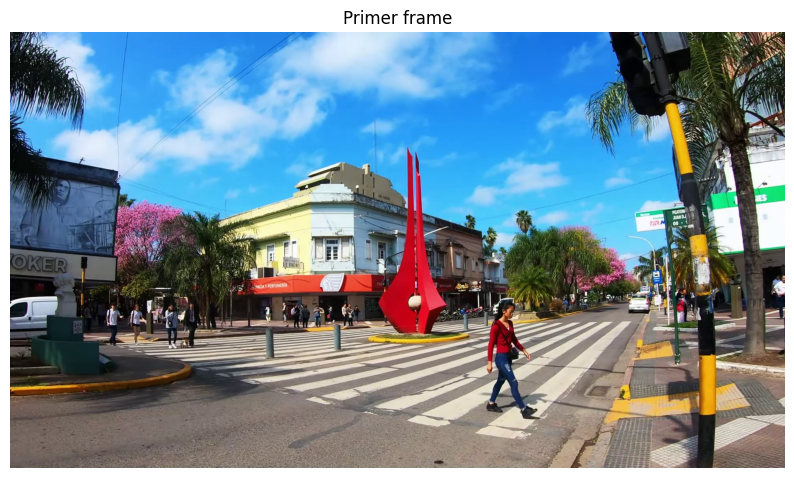

In [ ]:
# ============================================================
# CELDA 2 (video propio): carga del video
# ============================================================
import os, cv2
import matplotlib.pyplot as plt
from google.colab import files

print("Selecciona tu video (mp4):")
uploaded = files.upload()
VIDEO_PATH = "/content/" + next(iter(uploaded))

# Carpeta de salida separada para este video (la Celda 4 la necesita creada)
CONFIG["output_dir"] = "/content/output_video_propio"
os.makedirs(CONFIG["output_dir"], exist_ok=True)

cap = cv2.VideoCapture(VIDEO_PATH)
assert cap.isOpened(), f"No se pudo abrir el video: {VIDEO_PATH}"
FPS = cap.get(cv2.CAP_PROP_FPS) or 25.0
N_FRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
ok, FIRST_FRAME = cap.read()
cap.release()
assert ok, "No se pudo leer el primer frame"

print(f"Video     : {VIDEO_PATH}")
print(f"Resolucion: {W}x{H} | FPS: {FPS:.2f} | Frames: {N_FRAMES} | Duracion: {N_FRAMES / FPS:.1f} s")

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(FIRST_FRAME, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Primer frame")
plt.show()

linea de conteo

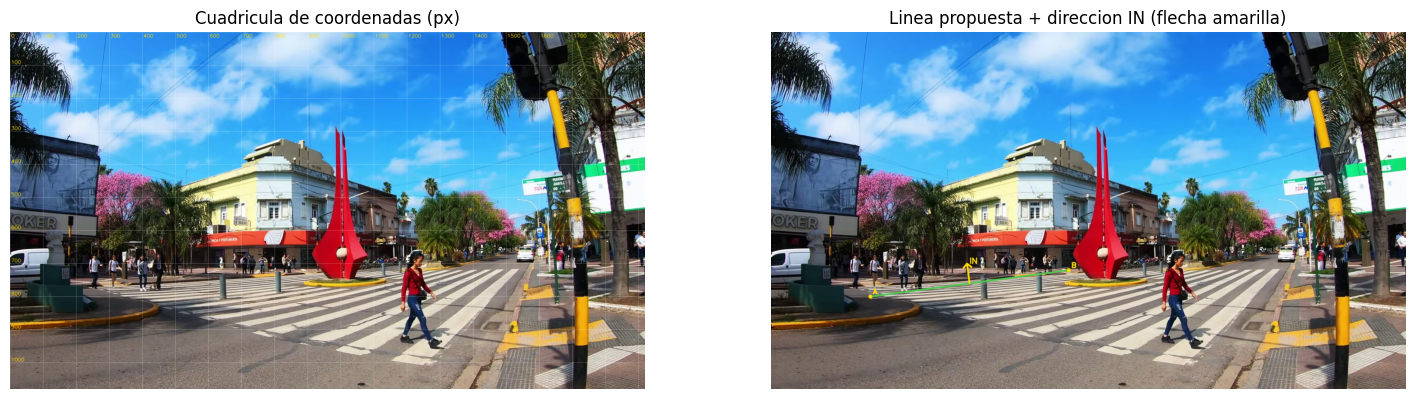

A=(300, 800)  B=(900, 720)  INVERT=False  HYSTERESIS_PX=8


In [ ]:
# ============================================================
# CELDA 3: Definicion de la linea de conteo (con vista previa)
# ============================================================
import importlib
import matplotlib.pyplot as plt
import pipeline as pl
importlib.reload(pl)

# 1) Mira la cuadricula y decide A y B (pixeles). Los valores de abajo son solo un ejemplo.
LINE_A = (300, 800)
LINE_B = (900, 720)
INVERT = False        # pon True si la flecha "IN" apunta al lado que tu consideras SALIDA
HYSTERESIS_PX = 8     # banda muerta alrededor de la linea (sube a 12-15 si ves jitter)

assert 0 <= LINE_A[0] < W and 0 <= LINE_B[0] < W and 0 <= LINE_A[1] < H and 0 <= LINE_B[1] < H, \
    "A y B deben estar dentro del frame"

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes[0].imshow(cv2.cvtColor(pl.draw_grid(FIRST_FRAME, step=100), cv2.COLOR_BGR2RGB))
axes[0].set_title("Cuadricula de coordenadas (px)")
axes[1].imshow(cv2.cvtColor(pl.draw_line_preview(FIRST_FRAME, LINE_A, LINE_B, INVERT, HYSTERESIS_PX),
                            cv2.COLOR_BGR2RGB))
axes[1].set_title("Linea propuesta + direccion IN (flecha amarilla)")
for ax in axes:
    ax.axis("off")
plt.show()
print(f"A={LINE_A}  B={LINE_B}  INVERT={INVERT}  HYSTERESIS_PX={HYSTERESIS_PX}")

In [ ]:
# ============================================================
# CELDA 4: Inferencia + tracking + cruce de linea + overlay (streaming frame a frame)
# ============================================================
import importlib
import crossing_counter, pipeline as pl
importlib.reload(crossing_counter); importlib.reload(pl)
from crossing_counter import CrossingCounter

counter = CrossingCounter(LINE_A, LINE_B, hysteresis_px=HYSTERESIS_PX,
                          count_once_per_id=True, invert=INVERT)
lz_step = pl.make_linezone(LINE_A, LINE_B)      # verificacion cruzada (None si no esta disponible)
RAW_VIDEO = os.path.join(CONFIG["output_dir"], "annotated_raw.mp4")

frames = pl.iter_tracked_frames(model, VIDEO_PATH, CONFIG)
result = pl.run_pipeline(frames, counter, RAW_VIDEO, FPS, LINE_A, LINE_B,
                         invert=INVERT, linezone_step=lz_step)

print("\n--- Resultado ---")
print(f"Frames procesados: {result['n_frames']} en {result['wall_s']:.1f} s "
      f"({result['n_frames'] / result['wall_s']:.1f} FPS extremo a extremo)")
print(f"IN = {counter.count_in} | OUT = {counter.count_out} | NETO = {counter.count_in - counter.count_out}")

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 200ms
Prepared 1 package in 47ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
  frame 100 | IN=0 OUT=0
  frame 200 | IN=0 OUT=2
  frame 300 | IN=0 OUT=3
  frame 400 | IN=3 OUT=4
  frame 500 | IN=3 OUT=6
  frame 600 | IN=4 OUT=7
  frame 700 | IN=4 OUT=8
  frame 800 | IN=4 OUT=8
  frame 900 | IN=6 OUT=8
  frame 1000 | IN=8 OUT=8
  frame 1100 | IN=8 OUT=10
  frame 1200 | IN=8 OUT=10
  frame 1300 | IN=8 OUT=10
  frame 1400 | IN=11 OUT=10
  frame 1500 | IN=11 OUT=11
  frame 1600 | IN=11 OUT=12
  frame 1700 | IN=11 OUT=14
  frame 1800 | IN=11 OUT=14
  frame 1900 | IN=12 OUT=14
  frame 2000 | IN=12 OUT=17
  frame 2100 | IN=12 OUT

In [ ]:
# ============================================================
# CELDA 5: Exportacion de video y metricas (CSV)
# ============================================================
import json
from IPython.display import Video, display

out_dir = CONFIG["output_dir"]
FINAL_VIDEO = pl.reencode_h264(RAW_VIDEO, os.path.join(out_dir, "annotated.mp4"))

events_df, perf_df, summary = pl.export_results(
    counter, result, FPS, out_dir,
    extra={"video": VIDEO_PATH, "model": CONFIG["model_name"], "imgsz": CONFIG["imgsz"],
           "conf": CONFIG["conf"], "line_a": LINE_A, "line_b": LINE_B,
           "invert": INVERT, "hysteresis_px": HYSTERESIS_PX})

print(json.dumps(summary, indent=2, default=str))
print("\nEventos de cruce:")
display(events_df)

if "linezone_in" in summary:
    print(f"\nVerificacion cruzada -> mio: IN={counter.count_in} OUT={counter.count_out} | "
          f"supervision.LineZone: IN={summary['linezone_in']} OUT={summary['linezone_out']}")
    print("LineZone no es unico por ID y no usa histeresis, asi que pequenas diferencias son esperables; "
          "diferencias grandes indican jitter o cambios de ID.")
if summary["dubious_ids"]:
    print(f"\nIDs con mas de un cruce (revisar jitter o cambio de ID): {summary['dubious_ids']}")

if FINAL_VIDEO.endswith("annotated.mp4") and os.path.getsize(FINAL_VIDEO) < 30e6:
    display(Video(FINAL_VIDEO, embed=True, width=800))
else:
    print("Video no incrustado (pesado o sin ffmpeg); descargalo abajo.")

from google.colab import files
for name in (FINAL_VIDEO, "events.csv", "perf.csv", "summary.json"):
    path = name if os.path.isabs(name) else os.path.join(out_dir, name)
    files.download(path)

{
  "count_in": 12,
  "count_out": 21,
  "net": -9,
  "unique_tracks": 523,
  "mean_track_len_frames": 59.7,
  "mean_track_len_s": 1.99,
  "dubious_ids": [
    268,
    275,
    380,
    386,
    662,
    1035,
    1102
  ],
  "n_frames": 2539,
  "fps_e2e": 21.07,
  "fps_detect_track": 38.49,
  "latency_total_ms_mean": 47.45,
  "latency_total_ms_p95": 72.93,
  "linezone_in": 44,
  "linezone_out": 48,
  "video": "/content/(1415) Resistencia Chaco Calle Peatonal en el Centro Comercial _ C\u00e1mara fija - YouTube - Google Chrome 2026-11-06 23-30-55.mp4",
  "model": "yolo11m.pt",
  "imgsz": 640,
  "conf": 0.3,
  "line_a": [
    300,
    800
  ],
  "line_b": [
    900,
    720
  ],
  "invert": false,
  "hysteresis_px": 8
}

Eventos de cruce:


,frame_idx,timestamp_s,track_id,direction,x,y,confidence,counted,n_crossings_id
0,120,3.961,5,OUT,442.5,793.1,0.725,True,1
1,138,4.561,4,OUT,397.0,795.4,0.703,True,1
2,247,8.189,133,OUT,772.2,775.9,0.644,True,1
3,321,10.653,40,IN,645.2,727.4,0.474,True,1
4,366,12.151,220,OUT,638.3,765.9,0.722,True,1
5,388,12.883,227,IN,537.4,758.1,0.699,True,1
6,398,13.216,244,IN,637.7,733.9,0.666,True,1
7,419,13.915,275,OUT,570.2,785.3,0.796,True,1
8,424,14.082,268,OUT,639.2,770.3,0.736,True,1
9,513,17.044,275,IN,577.7,746.6,0.510,False,2



Verificacion cruzada -> mio: IN=12 OUT=21 | supervision.LineZone: IN=44 OUT=48
LineZone no es unico por ID y no usa histeresis, asi que pequenas diferencias son esperables; diferencias grandes indican jitter o cambios de ID.

IDs con mas de un cruce (revisar jitter o cambio de ID): [268, 275, 380, 386, 662, 1035, 1102]
Video no incrustado (pesado o sin ffmpeg); descargalo abajo.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# CELDA 6: Comparacion con ground truth (nivel A: totales por direccion)
# ============================================================
GT_IN = 9    # <-- tu conteo manual de ENTRADAS  (con la misma linea de la Celda 3)
GT_OUT = 8   # <-- tu conteo manual de SALIDAS

if GT_IN is None or GT_OUT is None:
    print("Completa GT_IN y GT_OUT con tu conteo manual y vuelve a ejecutar esta celda.")
else:
    g = pl.compare_ground_truth(counter.count_in, counter.count_out, GT_IN, GT_OUT)
    print(f"Sistema     : IN={counter.count_in}  OUT={counter.count_out}")
    print(f"Ground truth: IN={GT_IN}  OUT={GT_OUT}\n")
    print(f"Exactitud total : {g['exactitud_total']:.1%}")
    print(f"Exactitud IN    : {g['exactitud_in']:.1%}   (error {g['error_in']:+d})")
    print(f"Exactitud OUT   : {g['exactitud_out']:.1%}   (error {g['error_out']:+d})")
    print(f"Error absoluto por direccion: {g['error_absoluto_por_direccion']}")
    if g["posible_compensacion"]:
        print("\nAVISO: el total coincide pero las direcciones no: hay errores que se compensan.")
    ok = g["exactitud_total"] >= 0.90 and g["error_absoluto_por_direccion"] <= max(1, 0.1 * (GT_IN + GT_OUT))
    print("\nCriterio de exito (exactitud >= 90 %):", "CUMPLE" if ok else "NO CUMPLE")
    import json
    with open(os.path.join(CONFIG["output_dir"], "ground_truth_report.json"), "w") as f:
        json.dump({"gt_in": GT_IN, "gt_out": GT_OUT, **g}, f, indent=2)

Sistema     : IN=12  OUT=21
Ground truth: IN=9  OUT=8

Exactitud total : 5.9%
Exactitud IN    : 66.7%   (error +3)
Exactitud OUT   : 0.0%   (error +13)
Error absoluto por direccion: 16

Criterio de exito (exactitud >= 90 %): NO CUMPLE
